# CS5720 Applications of Data Science: Coursework

## **Dataset Information**

The dataset consists of 8130 car models, with their features listed down below. These features can be used to predict the price of the car. 

Features:

- name: Full name of car's make and model
- year: Manufacturing year of the car
- selling_price: The price at which the car was sold (in Indian rupees)
- km_driven: Total distance the car has driven in kilometres (km)
- fuel: Type of fuel the car uses
  -'Petrol', 'Diesel', 'CNG', 'LPG'
- seller_type: Who is selling the car
  - 'Individual'(private seller), 'Dealer' (professional car dealer), 'Trustmark Dealer' (certified dealer)
- transmission: Gearbox type
  - 'Manual', 'Automatic'
- owner: Number of previous owner (or status)
  - 'First Owner', 'Second Owner', 'Third Owner', 'Fourth & Above Owner', 'Test Drive Car'
- mileage(km/ltr/kg): Fuel efficiency
- engine: Engine displacement, in cubic centimetres (CC)
- max_power: Maximum engine power, in brake horsepower (bhp)
- seats: Number of seats in the car

## **Importing required libraries**

In [5]:
# Standard
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualisation
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from scipy.stats import skew
plt.style.use('ggplot')
from sklearn.model_selection import learning_curve
from sklearn.model_selection import ShuffleSplit

# Outlier checking
from sklearn.neighbors import LocalOutlierFactor

# Normalisation
from sklearn.preprocessing import MinMaxScaler

# Standardisation
from sklearn.preprocessing import StandardScaler

# Encoding
from sklearn.preprocessing import OneHotEncoder

# Model Building
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from xgboost import XGBRegressor

## **Reading and understanding data**

In [7]:
# Read the file and create copy of data
data = pd.read_csv('CarPrices2025.csv')
cars = data.copy()

# Print number of rows and columns in dataset
print(
    f'There are {cars.shape[0]} rows and {cars.shape[1]} columns, '
    f'meaning there are {cars.shape[0]} cars and {cars.shape[1]} features.'
)

There are 8130 rows and 12 columns, meaning there are 8130 cars and 12 features.


In [8]:
# Inspect data, printing top 5 rows
cars.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


In [9]:
# Bottom 5 rows
cars.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
8125,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.50,1197.0,82.85,5.0
8126,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.80,1493.0,110,5.0
8127,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.30,1248.0,73.9,5.0
8128,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57,1396.0,70,5.0
8129,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57,1396.0,70,5.0


**Shape and features**

In [11]:
# Rows and columns 
cars.shape

(8130, 12)

In [12]:
# Number of rows
print('Rows    : ' , cars.shape[0]) 

 # Number of columns
print('Columns : ' , cars.shape[1]) 

Rows    :  8130
Columns :  12


In [13]:
# Listing feature names
print('Features :\n\n', cars.columns.tolist())

Features :

 ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats']


**Missing values**

In [15]:
# Finding missing values
print('Missing values :\n\n' ,cars.isnull().sum())

Missing values :

 name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64


In [16]:
# Calculating percentage of missing values in each column
print("Percentage of missing values:\n\n", 
      round(cars.isna().sum() / cars.isna().count() * 100, 2))

Percentage of missing values:

 name                  0.00
year                  0.00
selling_price         0.00
km_driven             0.00
fuel                  0.00
seller_type           0.00
transmission          0.00
owner                 0.00
mileage(km/ltr/kg)    2.72
engine                2.72
max_power             2.64
seats                 2.72
dtype: float64


In [17]:
# Listing columns with null values
col_with_null_values= cars.columns[cars.isnull().any().tolist()]
col_with_null_values

Index(['mileage(km/ltr/kg)', 'engine', 'max_power', 'seats'], dtype='object')

**Unique values**

In [19]:
# Number of unique values
print('Unique values:\n\n', cars.nunique())

Unique values:

 name                  2058
year                    32
selling_price          677
km_driven              921
fuel                     4
seller_type              3
transmission             2
owner                    5
mileage(km/ltr/kg)     381
engine                 121
max_power              320
seats                   11
dtype: int64


**Duplicated Rows**

In [21]:
# Number of duplicated values
print('Duplicated rows:', cars.duplicated().sum())

Duplicated rows: 1204


## **Data Preprocessing**

In [23]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8130 entries, 0 to 8129
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8130 non-null   object 
 1   year                8130 non-null   int64  
 2   selling_price       8130 non-null   int64  
 3   km_driven           8130 non-null   int64  
 4   fuel                8130 non-null   object 
 5   seller_type         8130 non-null   object 
 6   transmission        8130 non-null   object 
 7   owner               8130 non-null   object 
 8   mileage(km/ltr/kg)  7909 non-null   float64
 9   engine              7909 non-null   float64
 10  max_power           7915 non-null   object 
 11  seats               7909 non-null   float64
dtypes: float64(3), int64(3), object(6)
memory usage: 762.3+ KB


Data type for 'max_power' is object, because some values may have units assigned, hence stripping units.

**Handling missing values**

In [26]:
# Assessing missing values in each column
cars.isnull().sum()

name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64

In [27]:
# Calculating percentage of missing values in each column
print("Percentage of missing values:\n\n", 
      round(cars.isna().sum() / cars.isna().count() * 100, 2))

Percentage of missing values:

 name                  0.00
year                  0.00
selling_price         0.00
km_driven             0.00
fuel                  0.00
seller_type           0.00
transmission          0.00
owner                 0.00
mileage(km/ltr/kg)    2.72
engine                2.72
max_power             2.64
seats                 2.72
dtype: float64


As the perecentage of missing values is small (~2%) in the 4 rows, we may drop the rows with missing values. However, some features are more important than others, 'engine' and 'max_power' values may have a large impact on price of cars, whereas 'seats' and 'mileage(km/ltr/kg)' are relatively less important.

In [29]:
num_missing = cars.isnull().sum(axis=1)
num_missing.value_counts()

0    7909
4     215
3       6
Name: count, dtype: int64

In [30]:
#Investigating how many missing values per row are there for each variable
for n in num_missing.value_counts().sort_index().index:
    if n > 0:
        print("*" *30,f'\nFor the rows with exactly {n} missing values, NAs are found in:')
        n_miss_per_col = cars[num_missing == n].isnull().sum()
        print(n_miss_per_col[n_miss_per_col > 0])
        print('\n\n')

****************************** 
For the rows with exactly 3 missing values, NAs are found in:
mileage(km/ltr/kg)    6
engine                6
seats                 6
dtype: int64



****************************** 
For the rows with exactly 4 missing values, NAs are found in:
mileage(km/ltr/kg)    215
engine                215
max_power             215
seats                 215
dtype: int64





This confirms that certain columns and rows are missing values together, and specific rows are missing all these values in the specified columns. Hence, we may remove these rows with missing values.

In [32]:
cols_with_missing = [
    'mileage(km/ltr/kg)','engine',
    'max_power', 'seats'
]
cars = cars.dropna(subset=cols_with_missing).reset_index(drop=True)

In [33]:
# Verifying that missing values have been removed
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7909 entries, 0 to 7908
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                7909 non-null   object 
 1   year                7909 non-null   int64  
 2   selling_price       7909 non-null   int64  
 3   km_driven           7909 non-null   int64  
 4   fuel                7909 non-null   object 
 5   seller_type         7909 non-null   object 
 6   transmission        7909 non-null   object 
 7   owner               7909 non-null   object 
 8   mileage(km/ltr/kg)  7909 non-null   float64
 9   engine              7909 non-null   float64
 10  max_power           7909 non-null   object 
 11  seats               7909 non-null   float64
dtypes: float64(3), int64(3), object(6)
memory usage: 741.6+ KB


All missing values have been removed, leaving 7909 rows in the dataset.

**Handling duplicate rows**

In [36]:
# Calculating number of duplicated rows
print('Duplicated rows:', cars.duplicated().sum())

Duplicated rows: 1191


In [37]:
# Dropping duplicated rows and reset index
cars = cars.drop_duplicates(ignore_index=True)

In [38]:
# Verifying removal of duplicated rows
print('Duplicated rows:', cars.duplicated().sum())

Duplicated rows: 0


**Handling erroneous values and outliers**

In [40]:
cars.describe()

,year,selling_price,km_driven,mileage(km/ltr/kg),engine,seats
count,6718.000000,6.718000e+03,6.718000e+03,6718.00000,6718.000000,6718.000000
mean,2013.149449,5.263196e+05,7.340230e+04,19.46531,1430.891337,5.432123
std,27.600178,5.235398e+05,5.869980e+04,4.04915,493.493277,0.994442
min,200.000000,2.999900e+04,1.000000e+00,0.00000,624.000000,-5.000000
25%,2011.000000,2.500000e+05,3.800000e+04,16.80000,1197.000000,5.000000
50%,2014.000000,4.200000e+05,6.822150e+04,19.44000,1248.000000,5.000000
75%,2017.000000,6.500000e+05,1.000000e+05,22.50000,1498.000000,5.000000
max,2050.000000,1.000000e+07,2.360457e+06,42.00000,3604.000000,14.000000


**Erroneous values**:
- 'year' : This colummn has a minimum of 200 and a maximum of 2050, where both are statistically impossible, so be wary of these data.
- 'seats' : This column has a minimum of -5, there is also a value of 0 which can be fixed.

In [42]:
# Identifying row with 'year' < 1900
cars[cars['year']<=1900]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
3645,Maruti Alto 800 LXI,700,300000,80000,Petrol,Individual,Manual,First Owner,24.7,796.0,47.3,5.0
4329,Tata Aria Pride,200,525000,110000,Diesel,Individual,Manual,Second Owner,13.7,2179.0,138.1,7.0


After looking online, the earliest year the Tata Aria Pride was manufactured, was 2010, so we will change it to this value. The Maruti Alto however, has a year of supposed 700, which is impossible, and the value cannot be extrapolated, hence it may be removed.

In [44]:
cars = cars.drop(index=3645).reset_index(drop=True)

In [45]:
# Identifying row with 'year' < 1900
cars[cars['year']<=1900]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
4328,Tata Aria Pride,200,525000,110000,Diesel,Individual,Manual,Second Owner,13.7,2179.0,138.1,7.0


In [46]:
cars.loc[4328, 'year'] = 2010
cars.loc[4328]

name                  Tata Aria Pride
year                             2010
selling_price                  525000
km_driven                      110000
fuel                           Diesel
seller_type                Individual
transmission                   Manual
owner                    Second Owner
mileage(km/ltr/kg)               13.7
engine                         2179.0
max_power                       138.1
seats                             7.0
Name: 4328, dtype: object

In [47]:
# Identifying row with 'year' = 2050
cars[cars['year']>=2025]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
2461,Maruti 800 AC,2050,60000,80000,Petrol,Individual,Manual,Second Owner,16.1,796.0,37,4.0


After looking online, the Maruti 800 AC was manufactured between 2000-2014. We can assume that 2050 was a mistake for 2005, so we will change it.

In [49]:
cars.loc[2461, 'year'] = 2005
cars.loc[2461]

name                  Maruti 800 AC
year                           2005
selling_price                 60000
km_driven                     80000
fuel                         Petrol
seller_type              Individual
transmission                 Manual
owner                  Second Owner
mileage(km/ltr/kg)             16.1
engine                        796.0
max_power                        37
seats                           4.0
Name: 2461, dtype: object

In [50]:
# Verifying the 'year' column is complete
cars.describe()

,year,selling_price,km_driven,mileage(km/ltr/kg),engine,seats
count,6717.000000,6.717000e+03,6.717000e+03,6717.000000,6717.000000,6717.000000
mean,2013.607712,5.263532e+05,7.340132e+04,19.464530,1430.985857,5.432187
std,3.901774,5.235715e+05,5.870412e+04,4.048947,493.469198,0.994503
min,1994.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,-5.000000
25%,2011.000000,2.500000e+05,3.800000e+04,16.800000,1197.000000,5.000000
50%,2014.000000,4.200000e+05,6.820300e+04,19.440000,1248.000000,5.000000
75%,2017.000000,6.500000e+05,1.000000e+05,22.500000,1498.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,14.000000


In [51]:
# Identifying row with negative 'seats'
cars[cars['seats']<0]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
4674,Hyundai Accent VIVA CRDi,2003,145000,120000,Diesel,Individual,Manual,Fourth & Above Owner,13.1,1493.0,82,-5.0


In [52]:
# Correcting value
cars['seats'] = abs(cars['seats'])

In [53]:
# Verifying that no negative 'seats' are left
cars.describe()

,year,selling_price,km_driven,mileage(km/ltr/kg),engine,seats
count,6717.000000,6.717000e+03,6.717000e+03,6717.000000,6717.000000,6717.000000
mean,2013.607712,5.263532e+05,7.340132e+04,19.464530,1430.985857,5.433676
std,3.901774,5.235715e+05,5.870412e+04,4.048947,493.469198,0.986335
min,1994.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,0.000000
25%,2011.000000,2.500000e+05,3.800000e+04,16.800000,1197.000000,5.000000
50%,2014.000000,4.200000e+05,6.820300e+04,19.440000,1248.000000,5.000000
75%,2017.000000,6.500000e+05,1.000000e+05,22.500000,1498.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,14.000000


We now see that in the 'seats' column, there is a 0 value, which is impossible.

In [55]:
# Identifying row with 0 value
cars[cars['seats']<=0]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
4714,Chevrolet Enjoy TCDi LT 7 Seater,2013,355000,136000,Diesel,Individual,Manual,Second Owner,18.2,1248.0,73.8,0.0


It states in the name that the car is a 7 seater, hence we can change it.

In [57]:
cars.loc[4714, 'seats'] = 7
cars.loc[4714]

name                  Chevrolet Enjoy TCDi LT 7 Seater
year                                              2013
selling_price                                   355000
km_driven                                       136000
fuel                                            Diesel
seller_type                                 Individual
transmission                                    Manual
owner                                     Second Owner
mileage(km/ltr/kg)                                18.2
engine                                          1248.0
max_power                                         73.8
seats                                              7.0
Name: 4714, dtype: object

**Outliers**:
- 'selling_price' : There is one value of 10,000,000 rupees, be wary of this data.
- 'seats' : There is one value of 14 seats, be wary of this data.

'seats' has a value of 14, which we should take a closer look at.

In [60]:
cars[cars['seats']>=14]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
3843,Tata Winger Deluxe - Flat Roof (Non-AC),2010,235000,50000,Diesel,Individual,Manual,First Owner,10.71,1948.0,90,14.0


After taking a look online, it is a 14 seater, but as it is still an outlier, we may remove it.

In [62]:
cars = cars.drop(index=3843).reset_index(drop=True)

In [63]:
# Verifying all erroneous data and outliers have been dealt with
cars.describe()

,year,selling_price,km_driven,mileage(km/ltr/kg),engine,seats
count,6716.000000,6.716000e+03,6.716000e+03,6716.000000,6716.000000,6716.000000
mean,2013.608249,5.263966e+05,7.340480e+04,19.465834,1430.908874,5.433443
std,3.901816,5.235984e+05,5.870779e+04,4.047839,493.465602,0.978796
min,1994.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,2.000000
25%,2011.000000,2.500000e+05,3.798600e+04,16.800000,1197.000000,5.000000
50%,2014.000000,4.200000e+05,6.822150e+04,19.440000,1248.000000,5.000000
75%,2017.000000,6.500000e+05,1.000000e+05,22.500000,1498.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,10.000000


**Clean dataset**

In [65]:
cars.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


In [66]:
print(
    f'There are {cars.shape[0]} rows and {cars.shape[1]} columns, '
    f'meaning there are {cars.shape[0]} cars and {cars.shape[1]} features.'
)

There are 6716 rows and 12 columns, meaning there are 6716 cars and 12 features.


## **Feature Engineering**

**Converting datatype**

In [69]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6716 entries, 0 to 6715
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                6716 non-null   object 
 1   year                6716 non-null   int64  
 2   selling_price       6716 non-null   int64  
 3   km_driven           6716 non-null   int64  
 4   fuel                6716 non-null   object 
 5   seller_type         6716 non-null   object 
 6   transmission        6716 non-null   object 
 7   owner               6716 non-null   object 
 8   mileage(km/ltr/kg)  6716 non-null   float64
 9   engine              6716 non-null   float64
 10  max_power           6716 non-null   object 
 11  seats               6716 non-null   float64
dtypes: float64(3), int64(3), object(6)
memory usage: 629.8+ KB


In [70]:
# Converting object data type to category data type
cars['fuel'] = cars['fuel'].astype('category')
cars['seller_type'] = cars['seller_type'].astype('category')
cars['transmission'] = cars['transmission'].astype('category')
cars['owner'] = cars['owner'].astype('category')

In [71]:
# max_power requires work, as it's a column of numbers, but is stored as object data type
conv = pd.to_numeric(cars['max_power'], errors='coerce')
mask_bad = conv.isna() & cars['max_power'].notna()
df_non_numeric = cars[mask_bad]
print(df_non_numeric)

                 name  year  selling_price  km_driven fuel seller_type  \
4140  Maruti Omni CNG  2000          80000     100000  CNG  Individual   

     transmission         owner  mileage(km/ltr/kg)  engine max_power  seats  
4140       Manual  Second Owner                10.9   796.0              8.0  


In [72]:
# Converting every entry to float
cars['max_power'] = pd.to_numeric(cars['max_power'], errors='coerce')
print(cars['max_power'].dtype)

float64


**Handling 'year' to get 'car_age'**

Currently, 'year' contains values of what year the car was manufactured. Creating two new columns, 'age' and 'current year', can help to understand the age of the car and how it affects prices. 'car_age' would equal 'current_year' - 'year'.

In [75]:
cars['current_year'] = 2025
cars['car_age'] = cars['current_year'] - cars['year']
cars.drop('current_year', axis=1, inplace=True)
cars.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,car_age
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,11
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,11
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,19
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,15
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,18


**Handling 'name' column**

'name' is currently a combination of the car's brand and model. A car's brand affects the price of the car, so by seperating the car's brand and model, it is possible to understand the role the car's brand plays.

In [78]:
# Seperating 'brand' from 'name'
cars['brand'] = cars['name'].str.split(' ').str[0] 

# Separating 'model' from 'name'
cars['model'] = cars['name'].str.split(' ').str[1] + cars['name'].str.split(' ').str[2]

In [79]:
# Listing the different car brands
cars.brand.unique()

array(['Maruti', 'Skoda', 'Honda', 'Hyundai', 'Toyota', 'Ford', 'Renault',
       'Mahindra', 'Tata', 'Chevrolet', 'Datsun', 'Jeep', 'Mercedes-Benz',
       'Mitsubishi', 'Audi', 'Volkswagen', 'BMW', 'Nissan', 'Lexus',
       'Jaguar', 'Land', 'MG', 'Volvo', 'Daewoo', 'Kia', 'Fiat', 'Force',
       'Ambassador', 'Ashok', 'Isuzu', 'Opel'], dtype=object)

In [80]:
cars.brand.nunique()

31

In [81]:
cars.groupby(cars.brand).size().sort_values(ascending=False)

brand
Maruti           2089
Hyundai          1214
Mahindra          709
Tata              632
Honda             361
Ford              353
Toyota            324
Chevrolet         216
Renault           206
Volkswagen        173
Nissan             73
Skoda              69
Datsun             57
Mercedes-Benz      46
BMW                45
Fiat               39
Audi               33
Jeep               22
Mitsubishi         11
Volvo               9
Jaguar              8
Ambassador          4
Isuzu               4
Force               4
MG                  3
Land                3
Daewoo              3
Kia                 3
Lexus               1
Opel                1
Ashok               1
dtype: int64

Hence, there are 31 different car brands, with majority of ~30% of selling cars being Maruti brand.

In [83]:
# Checking for null values in 'model'
cars.model.isnull().sum()

0

In [84]:
cars.model.nunique()

664

In [85]:
cars.groupby(cars.model).size().sort_values(ascending =False)

model
SwiftDzire     346
WagonR         245
Grandi10       151
Innova2.5      147
Alto800        132
              ... 
GurkhaHard       1
Grand2000        1
Grand1500        1
SuperbLK         1
LandCruiser      1
Length: 664, dtype: int64

Hence, there are 665 different models of car and the Swift Dzire is the most prominent model at over 50%.

In [87]:
cars.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,car_age,brand,model
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,11,Maruti,SwiftDzire
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,11,Skoda,Rapid1.5
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,19,Honda,City2017-2020
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,15,Hyundai,i20Sportz
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,18,Maruti,SwiftVXI


## **Exploratory Data Analysis**

In [89]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6716 entries, 0 to 6715
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   name                6716 non-null   object  
 1   year                6716 non-null   int64   
 2   selling_price       6716 non-null   int64   
 3   km_driven           6716 non-null   int64   
 4   fuel                6716 non-null   category
 5   seller_type         6716 non-null   category
 6   transmission        6716 non-null   category
 7   owner               6716 non-null   category
 8   mileage(km/ltr/kg)  6716 non-null   float64 
 9   engine              6716 non-null   float64 
 10  max_power           6715 non-null   float64 
 11  seats               6716 non-null   float64 
 12  car_age             6716 non-null   int64   
 13  brand               6716 non-null   object  
 14  model               6716 non-null   object  
dtypes: category(4), float64(4), int64(4), 

In [90]:
cars.describe()

,year,selling_price,km_driven,mileage(km/ltr/kg),engine,max_power,seats,car_age
count,6716.000000,6.716000e+03,6.716000e+03,6716.000000,6716.000000,6715.000000,6716.000000,6716.000000
mean,2013.608249,5.263966e+05,7.340480e+04,19.465834,1430.908874,87.771794,5.433443,11.391751
std,3.901816,5.235984e+05,5.870779e+04,4.047839,493.465602,31.725424,0.978796,3.901816
min,1994.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,32.800000,2.000000,5.000000
25%,2011.000000,2.500000e+05,3.798600e+04,16.800000,1197.000000,67.100000,5.000000,8.000000
50%,2014.000000,4.200000e+05,6.822150e+04,19.440000,1248.000000,81.830000,5.000000,11.000000
75%,2017.000000,6.500000e+05,1.000000e+05,22.500000,1498.000000,100.000000,5.000000,14.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,10.000000,31.000000


**Statistical Observations**

'year'
- Cars cluster tightly between 2011 (25 %) and 2017 (75 %), with a median of 2014 and mean ≈ 2013.6.
- Slight left skew (mean < median) reflects a small tail of older models dating back to 1994.

'selling_price' (₹)
- Prices are heavily right‐skewed: half of listings lie between ₹250 K and ₹650 K (median ₹420 K).
- A few luxury models push the tail out to ₹10 M, inflating the mean.

'km_driven'
- Odometers largely fall under 100 K km (IQR 38 K - 100 K, median ≈ 68 K).
- A small number of very high‐mileage cars (up to 2.36 M km) create a right skew.

'mileage(km/ltr/kg)'
- Fuel efficiency is tightly centered (IQR 16.8–22.5 km/unit, median ≈ 19.44), yielding a nearly symmetric distribution with only a mild right tail from high‐efficiency outliers.

'engine' (cc)
- Most engines sit between 1197 cc (25 %) and 1498 cc (75 %) with a median of 1248 cc.
- The distribution is right‐skewed by a few large‐displacement models up to 3604 cc.

'max_power' (bhp)
- Typical power ranges from 67.1 bhp to 100 bhp for the middle 50 % (median ≈ 81.8 bhp).
- A few high‐performance cars (up to 400 bhp) produce a strong right‐skew.

'seats'
- The distribution is almost a spike at five seats (25 %, 50 %, and 75 % all at 5).
- Only rare tails to two‐seat sports cars or seven- and fourteen-seat vehicles.

'car_age' (years)
- Car ages cluster between 8 and 14 years (median 11, mean ≈ 11.4).
- Slight right skew from older vehicles reaching up to 31 years.

**Distribution graphs**

**Numerical columns**

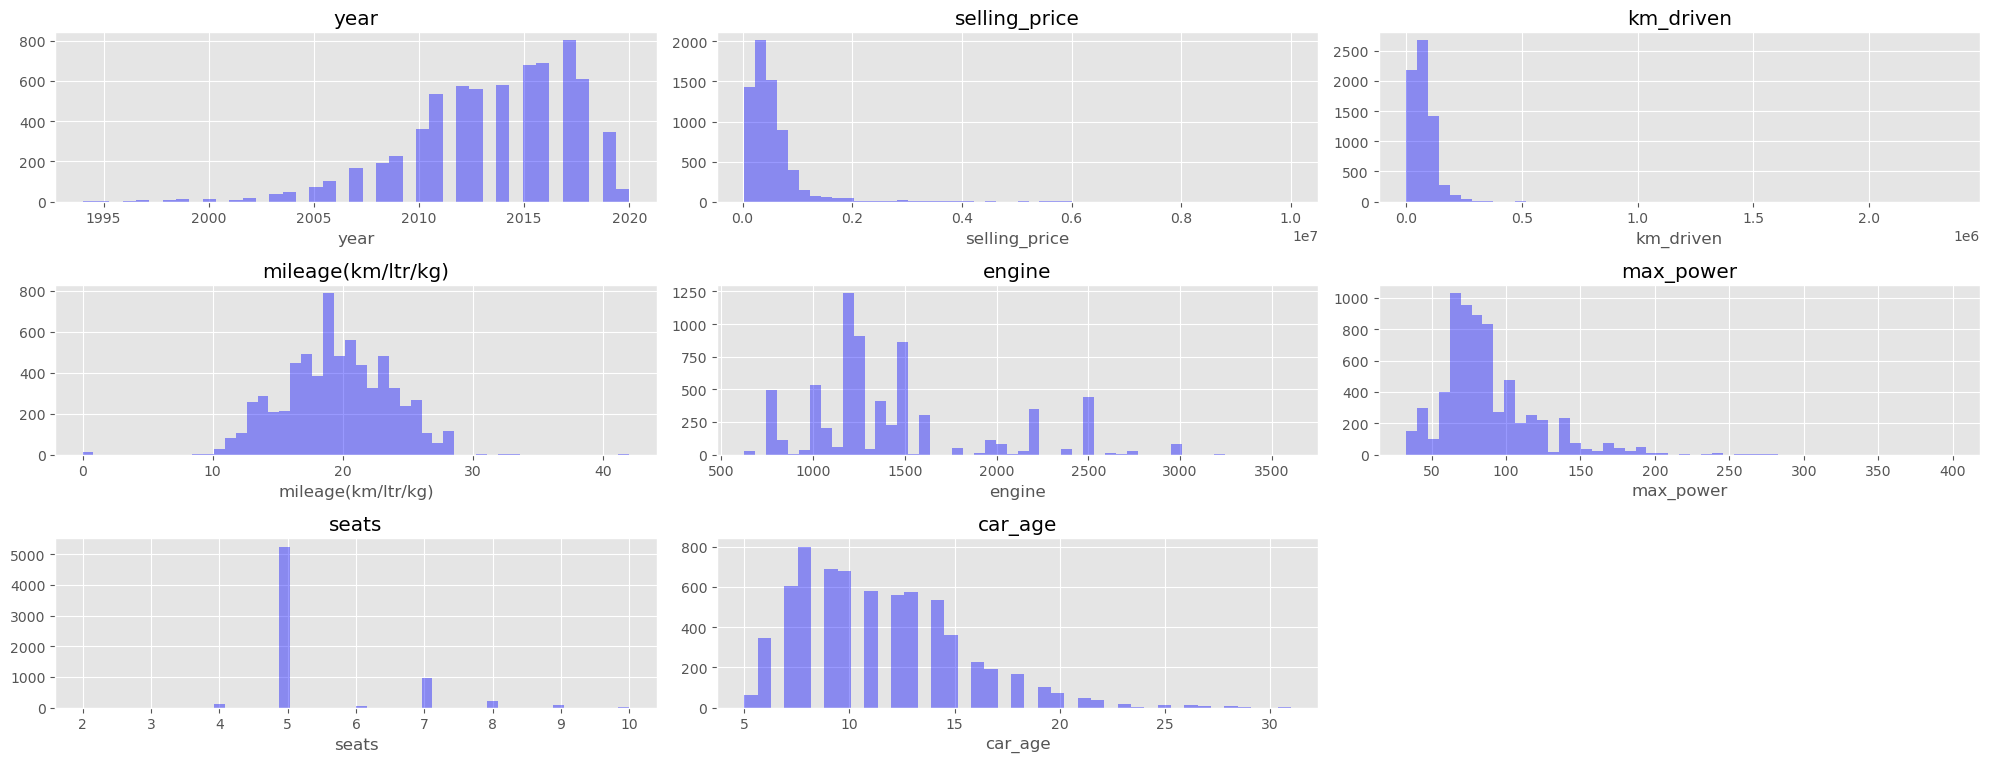

In [95]:
plt.style.use('ggplot')
# Select all quantitative columns to check the spread
numeric_columns = cars.select_dtypes(include=np.number).columns.tolist()
plt.figure(figsize=(20,25))

for i, variable in enumerate(numeric_columns):
    plt.subplot(10,3,i+1)
                       
    sns.distplot(cars[variable],kde=False,color='blue')
    plt.tight_layout()
    plt.title(variable)

Numerical Observations:

- 'year' is left skewed and has outliers on the lower side.
- 'selling_price' is right skewed, with outliers on upper side.
- 'km_driven' is right skewed.
- 'mileage' is nearly normally/gaussion distribution, with a couple outliers either side.
- 'engine', 'max_power' and 'car_age' are right skewed, with outliers on upper side.

**Utilising log transformation for right/left skewed**

In [99]:
# Listing skewed columns
skewed_cols = ['year', 'selling_price',
               'km_driven', 'engine',
               'max_power', 'car_age'
              ]

# Check that they’re all ≥ 0
print(cars[skewed_cols].min())

# Apply log1p (i.e. log(1 + x)) to handle zeros safely
cars_log = cars.copy()
cars_log[skewed_cols] = cars_log[skewed_cols].apply(np.log1p)

# Verify the effect on skewness
print("Skew before:\n", cars[skewed_cols].skew())
print("Skew after:\n", cars_log[skewed_cols].skew())

year              1994.0
selling_price    29999.0
km_driven            1.0
engine             624.0
max_power           32.8
car_age              5.0
dtype: float64
Skew before:
 year             -0.933810
selling_price     5.569947
km_driven        11.914902
engine            1.216235
max_power         1.711467
car_age           0.933810
dtype: float64
Skew after:
 year            -0.940511
selling_price   -0.144069
km_driven       -1.309709
engine           0.458377
max_power        0.281421
car_age          0.151066
dtype: float64


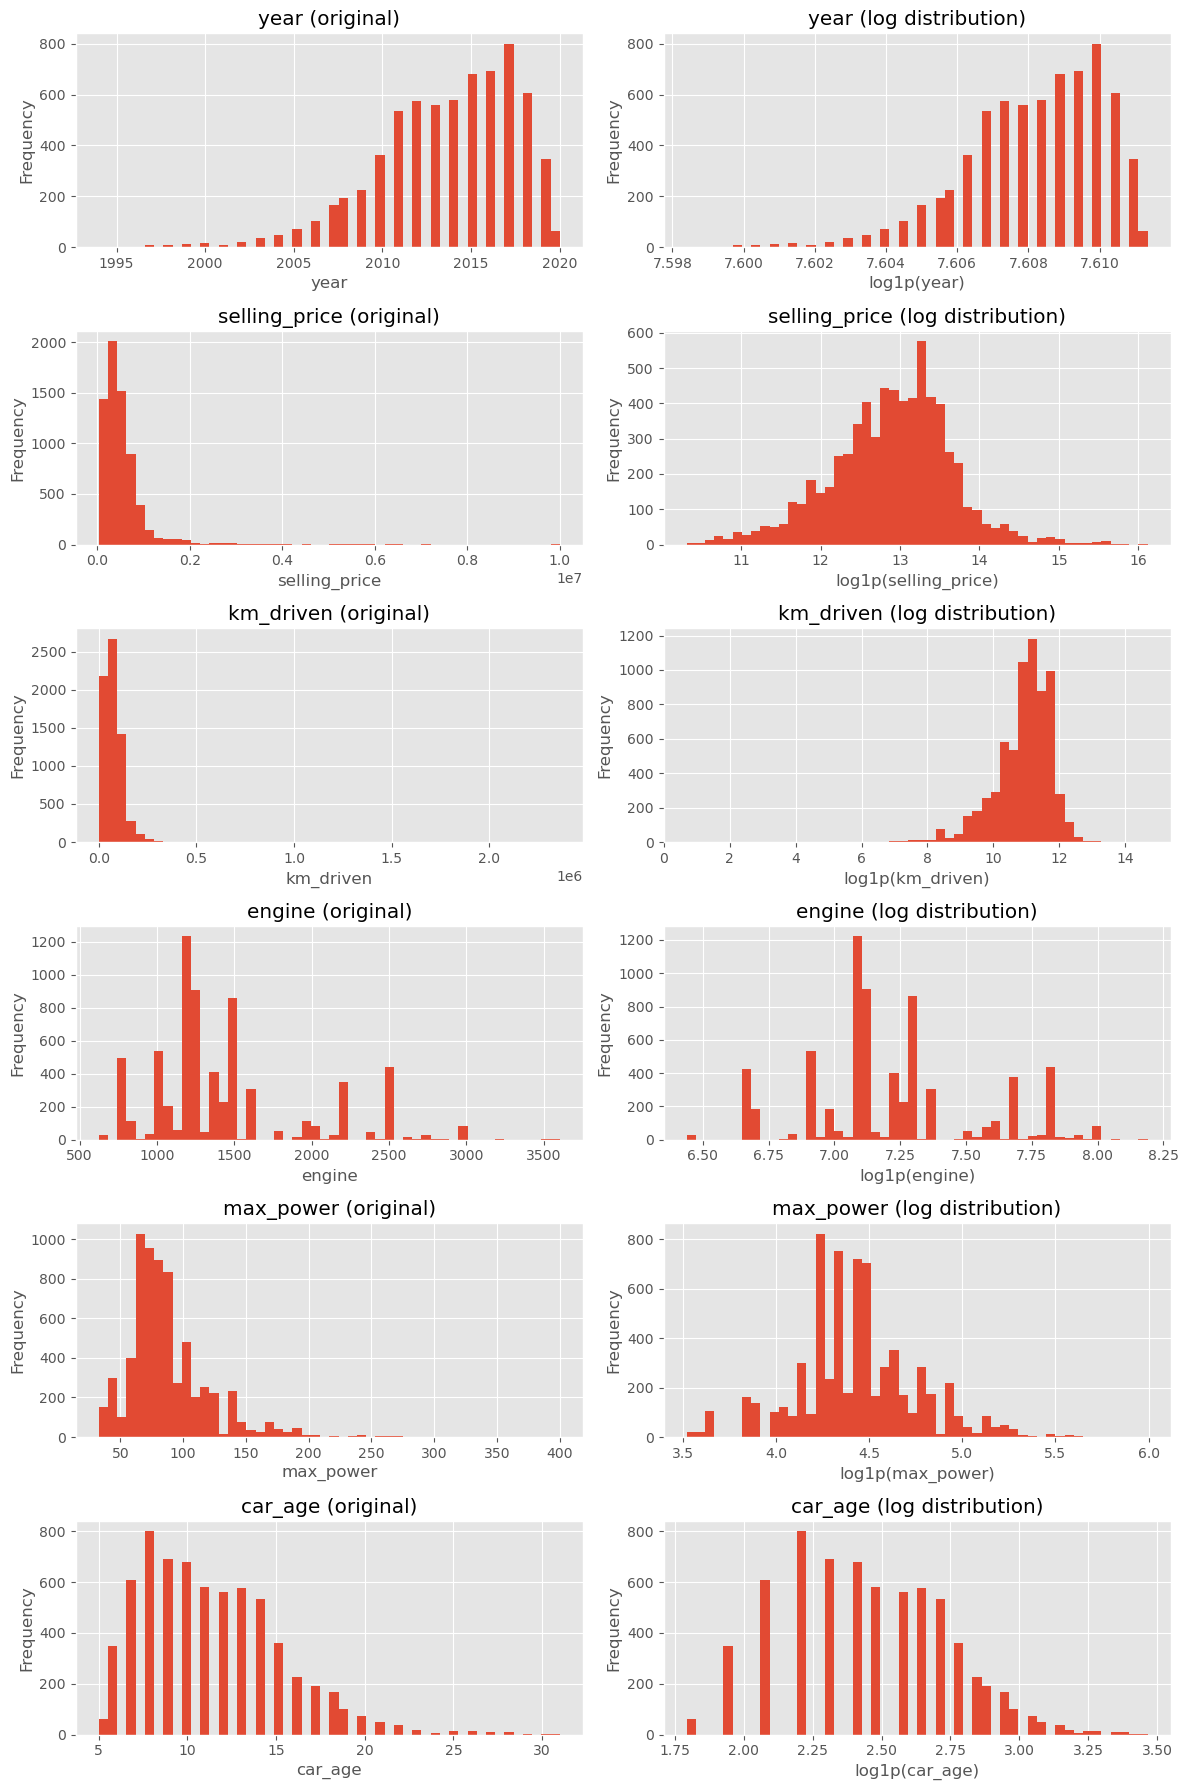

In [100]:
plt.figure(figsize=(12, len(skewed_cols)*3))
for i, variable in enumerate(skewed_cols):
    # original
    plt.subplot(len(skewed_cols), 2, 2*i + 1)
    plt.hist(cars[variable], bins=50)
    plt.title(f'{variable} (original)')
    plt.xlabel(variable)
    plt.ylabel('Frequency')

    # log1p
    plt.subplot(len(skewed_cols), 2, 2*i + 2)
    plt.hist(np.log1p(cars[variable]), bins=50)
    plt.title(f'{variable} (log distribution)')
    plt.xlabel(f'log1p({variable})')
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

Observations:

'selling_price' & 'km_driven'
- Before: very heavy right tails (skew >> 1).
- After: nearly symmetric (slightly left-skewed), so log transformation effectively normalized these distributions.

'engine' & 'max_power' 
- Before: moderate right skew (1-2).
- After: reduced to slight right skew(<0.5), but not completely normal.

'year' & 'car_age'
- Both show a slight left skew(<0) before and remain so after, as the age distribution is naturally bounded (none newer than 2020, none less than 1994.

Takeaways:
- Log1p works best on truly continuous, heavily skewed features (price, odometer) by compressing their long right-tails into something near symmetric.
- Features with discrete 'lumpy' values (engine cc, bhp) will rarely become perfectly Gaussian with a simple log; they may require binning or categorical treatment.
- Bounded/age-type features (year, car_age) often retain slight skew unless you apply other transforms or treat them differently.

Moving forward, you can:
- Keep using log1p + standard scaling for price and km.
- Consider alternate transforms or binning for engine and power.
- Leave year/car_age as standardized numeric inputs or encode as categories.

**Categorical columns**

In [103]:
# Checking non-numerical columns for category list
cars.select_dtypes(exclude=np.number).columns.tolist()

['name', 'fuel', 'seller_type', 'transmission', 'owner', 'brand', 'model']

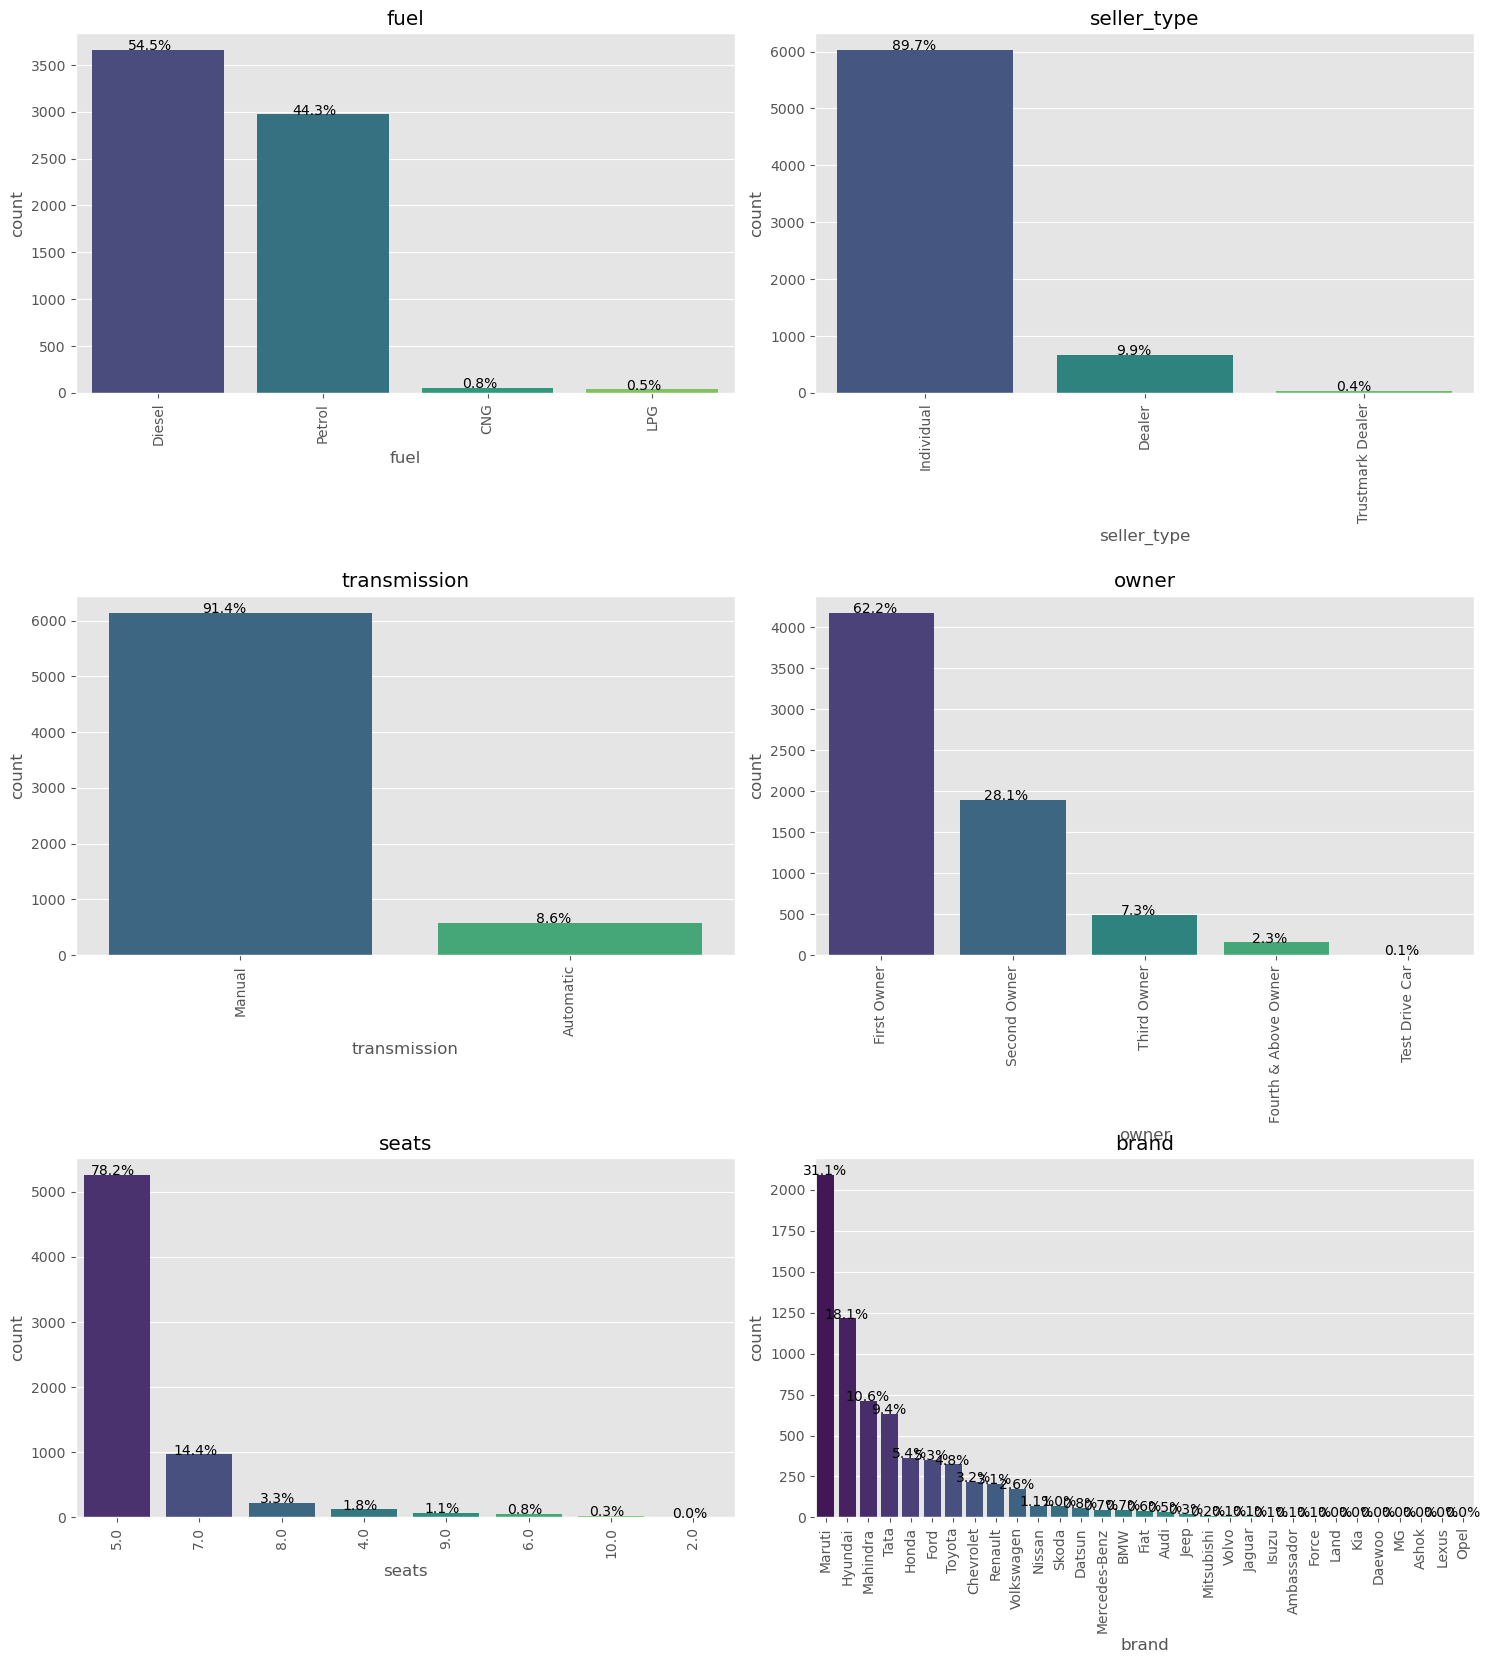

In [104]:
# Adding numerical columns to category list
ctg_columns = ['fuel', 'seller_type',
               'transmission', 'owner',
               'seats', 'brand'
              ] 

plt.figure(figsize=(15,21))

# Visualising categorical columns
for i, variable in enumerate(ctg_columns):
    plt.subplot(4,2,i+1)
    order = cars[variable].value_counts(ascending=False).index    
    ax=sns.countplot(x=cars[variable], data=cars ,
                     order=order ,palette='viridis'
                    )
    for p in ax.patches:
        percentage = '{:.1f}%'.format(100 * p.get_height()/len(cars[variable]))
        x = p.get_x() + p.get_width() / 2 - 0.05
        y = p.get_y() + p.get_height()
        plt.annotate(percentage, (x, y),ha='center')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.title(variable)

Categorical Observations:

- ~55 % of cars available have fuel type as Diesel.
- ~90 % cars are sold by individuals (private sellers).
- ~91 % cars available for sale have manual transmission.
- ~52 % of cars available for purchase are first-owned cars.
- ~78 % of the cars have 5 seats.
- ~49 % of cars available are from Maruti and Hyundai brands.

**Price vs Numeric Columns**

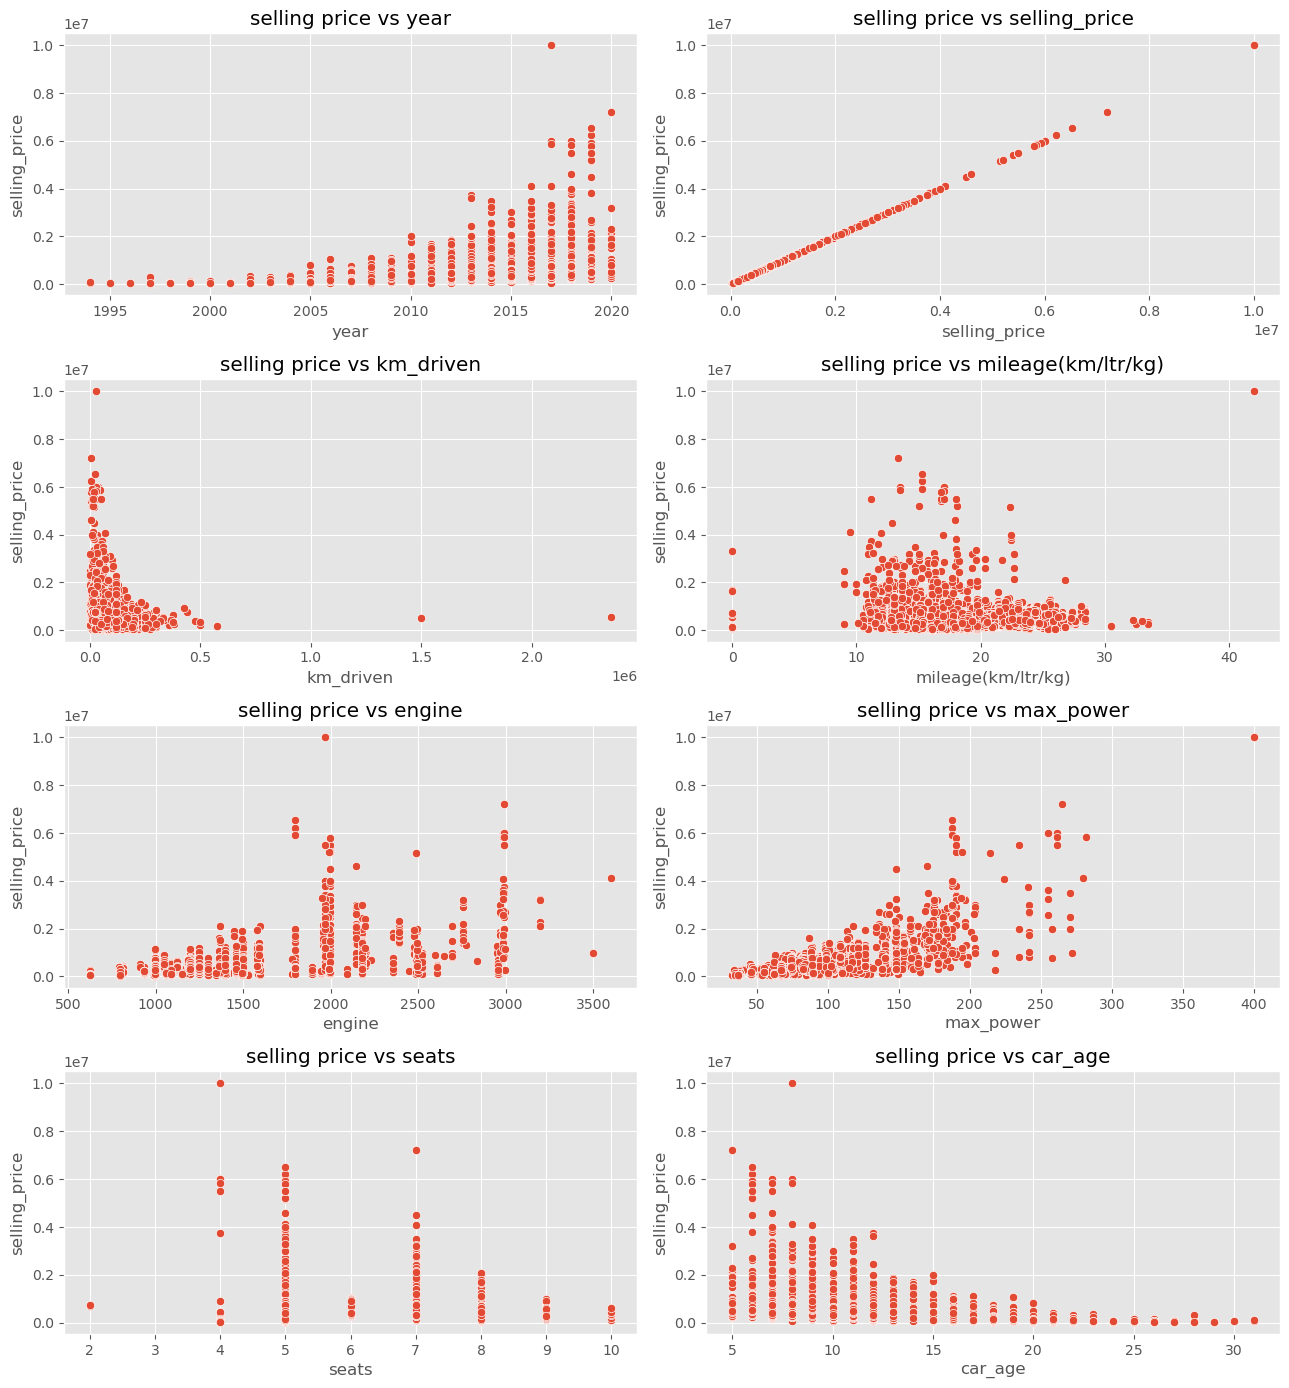

In [108]:
numeric_columns = cars.select_dtypes(include=np.number).columns.tolist()
plt.figure(figsize=(13,17))

for i, variable in enumerate(numeric_columns):
    plt.subplot(5,2,i+1)
    sns.scatterplot(x=cars[variable],
                    y=cars['selling_price']).set(title='selling price vs '
                                                 + variable)
    plt.tight_layout()

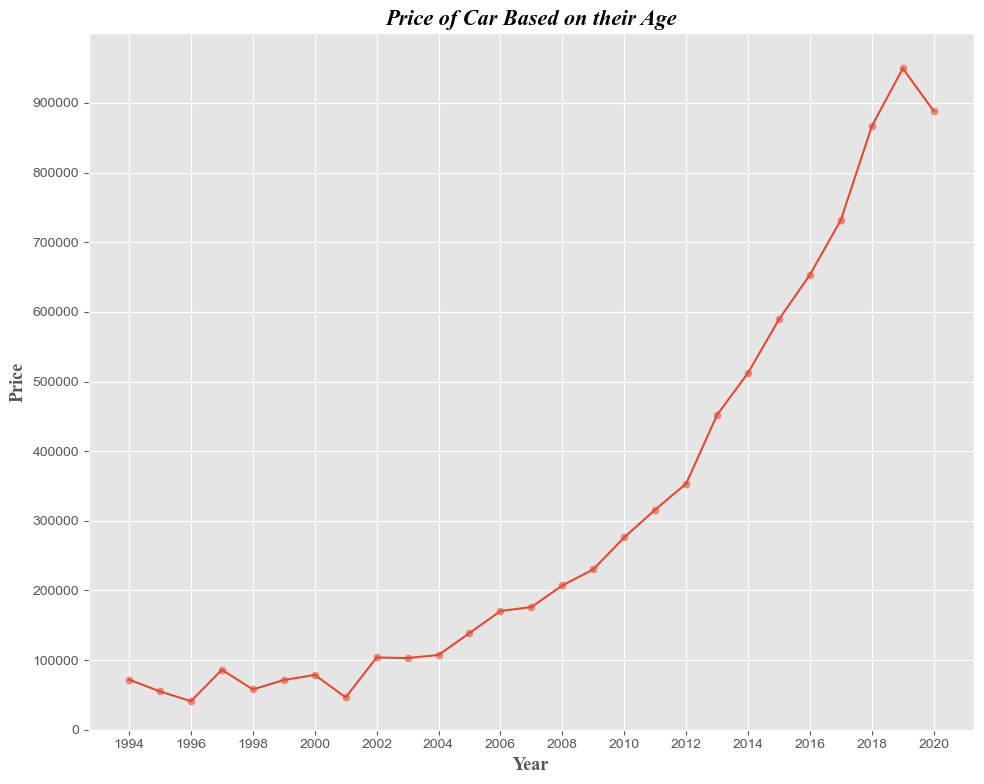

In [109]:
# selling_price vs year
year_price= pd.DataFrame(cars.groupby(by='year')
                         ['selling_price'].mean()).reset_index()
plt.figure(figsize=(10,8))
sns.lineplot(data=year_price, x= 'year', y='selling_price')
sns.scatterplot(data=year_price, x= 'year', y='selling_price', alpha=0.6)
plt.xticks(range(1994, 2022,2))
plt.yticks(range(0,1000000, 100000))
plt.ylim(0,1000000)
plt.xlabel('Year', fontdict={'family': 'Times New Roman',
                             'size':13, 'weight': 'bold'})
plt.ylabel('Price', fontdict={'family': 'Times New Roman',
                              'size':13, 'weight': 'bold'})
plt.title('Price of Car Based on their Age', fontdict={'family': 'Times New Roman',
                                                       'size':16, 'weight': 'bold', 'style': 'oblique'})
sns.set_theme('notebook')
sns.set_style('whitegrid')
plt.tight_layout()
plt.show()

**Correlation Heatmap**

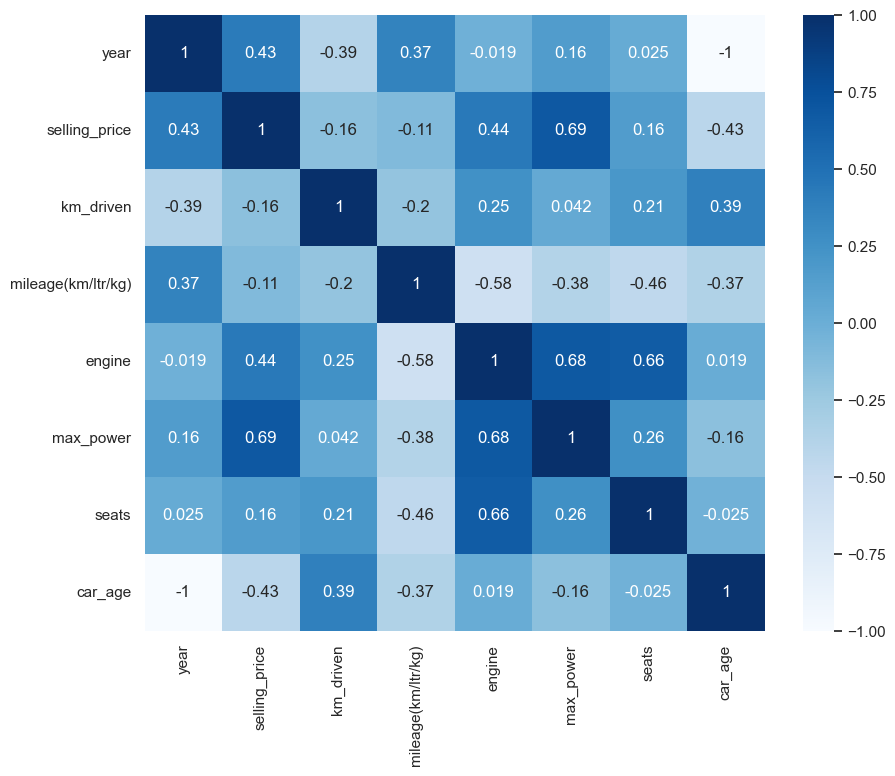

In [111]:
correlation_matrix = cars.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix, annot=True, cmap='Blues', vmin=-1)
plt.show()

## **Normalisation and Standardisation**

- By normalising a dataset, it scales the input features of a dataset into a range of optimal precision [0,1].
- By standardisation, the input features are scaled seperately, to shift the distribution to a standard normal distribution.
  
Both of these functions are used only on numerical features, categorical columns will have an alternative method.

In [114]:
# Removing target feature from numeric input columns
input_num_cols = cars.select_dtypes(include=np.number).columns.tolist()
input_num_cols.remove('selling_price')

**Normalising using MinMaxScaler**

In [116]:
# Scaling numeric input features
trans = MinMaxScaler(feature_range=(0,1))
scaled_array = trans.fit_transform(cars[input_num_cols])

# Get datset with same index and column names
norm_cars = pd.DataFrame(scaled_array,
                   columns=input_num_cols,
                   index=cars.index)

# Merging into original dataset
scaled_cars_n = cars
scaled_cars_n[input_num_cols] = norm_cars

# Inspect all numerical values are between 0 and 1
norm_cars.describe()

,year,km_driven,mileage(km/ltr/kg),engine,max_power,seats,car_age
count,6716.000000,6716.000000,6716.000000,6716.000000,6715.000000,6716.000000,6716.000000
mean,0.754163,0.031097,0.463472,0.270775,0.149705,0.429180,0.245837
std,0.150070,0.024871,0.096377,0.165592,0.086398,0.122349,0.150070
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.653846,0.016092,0.400000,0.192282,0.093410,0.375000,0.115385
50%,0.769231,0.028901,0.462857,0.209396,0.133524,0.375000,0.230769
75%,0.884615,0.042364,0.535714,0.293289,0.183007,0.375000,0.346154
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [117]:
# Verifying values don't go below 0
column_mins = norm_cars.min(numeric_only=True)
column_mins

year                  0.0
km_driven             0.0
mileage(km/ltr/kg)    0.0
engine                0.0
max_power             0.0
seats                 0.0
car_age               0.0
dtype: float64

**Standardising using StandardScaler**

Standardisation acts on the assumption that all data is Gaussian. As seen earlier on, only 2 or 3 numerical columns are roughly Gaussian. Standardisation may work on these columns, but for the others a different method is required.

In [120]:
# Scaling and fitting to data
scaler = StandardScaler()
scaled_array = scaler.fit_transform(cars[input_num_cols])

# Reconstruct a dataset with the same index & column names
stand_cars = pd.DataFrame(scaled_array,
                         columns=input_num_cols,
                         index=cars.index
                         )

# Merge back into original dataset copy
cars_scaled_s = cars
cars_scaled_s[input_num_cols] = stand_cars

# Inspect the result
stand_cars.describe()

,year,km_driven,mileage(km/ltr/kg),engine,max_power,seats,car_age
count,6.716000e+03,6.716000e+03,6.716000e+03,6.716000e+03,6.715000e+03,6.716000e+03,6.716000e+03
mean,8.040686e-17,-2.327567e-17,1.195523e-16,-1.851474e-17,-2.116285e-17,-4.020343e-17,-2.010172e-16
std,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00,1.000074e+00
min,-5.025790e+00,-1.250418e+00,-4.809303e+00,-1.635309e+00,-1.732865e+00,-3.508084e+00,-1.638270e+00
25%,-6.685202e-01,-6.033515e-01,-6.586310e-01,-4.740478e-01,-6.516330e-01,-4.428653e-01,-8.693396e-01
50%,1.004097e-01,-8.829638e-02,-6.382604e-03,-3.706895e-01,-1.873020e-01,-4.428653e-01,-1.004097e-01
75%,8.693396e-01,4.530434e-01,7.496326e-01,1.359692e-01,3.854674e-01,-4.428653e-01,6.685202e-01
max,1.638270e+00,3.895944e+01,5.567377e+00,4.404062e+00,9.842310e+00,4.665832e+00,5.025790e+00


In [121]:
# Verifying mean is ~0 and standard deviation is ~1
print("Means:", stand_cars.mean().round(3).to_dict())
print("Stds:",  stand_cars.std().round(3).to_dict())

Means: {'year': 0.0, 'km_driven': -0.0, 'mileage(km/ltr/kg)': 0.0, 'engine': -0.0, 'max_power': -0.0, 'seats': -0.0, 'car_age': -0.0}
Stds: {'year': 1.0, 'km_driven': 1.0, 'mileage(km/ltr/kg)': 1.0, 'engine': 1.0, 'max_power': 1.0, 'seats': 1.0, 'car_age': 1.0}


In [122]:
# Verifying values
column_mins = cars_scaled_s.min(numeric_only=True)
column_mins

year                     -5.025790
selling_price         29999.000000
km_driven                -1.250418
mileage(km/ltr/kg)       -4.809303
engine                   -1.635309
max_power                -1.732865
seats                    -3.508084
car_age                  -1.638270
dtype: float64

Negative values here are expected, as MinMax Scaling originally scales all data to bounds [0,1], and standardising after centers the distribution at 0. This means that for any negative values, they are just below the mean. They encode how far below the mean a data point lies, crucial for machine-learning algorithms.

In [124]:
cars.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,car_age,brand,model
0,Maruti Swift Dzire VDI,0.10041,450000,1.228126,Diesel,Individual,Manual,First Owner,0.971990,-0.370689,-0.434126,-0.442865,-0.10041,Maruti,SwiftDzire
1,Skoda Rapid 1.5 TDI Ambition,0.10041,370000,0.793739,Diesel,Individual,Manual,Second Owner,0.413626,0.135969,0.496428,-0.442865,-0.10041,Skoda,Rapid1.5
2,Honda City 2017-2020 EXi,-1.95007,158000,1.134435,Petrol,Individual,Manual,Third Owner,-0.436274,0.133943,-0.308034,-0.442865,1.95007,Honda,City2017-2020
3,Hyundai i20 Sportz Diesel,-0.92483,225000,0.912983,Diesel,Individual,Manual,First Owner,0.873165,-0.070748,0.070239,-0.442865,0.92483,Hyundai,i20Sportz
4,Maruti Swift VXI BSIII,-1.69376,130000,0.793739,Petrol,Individual,Manual,First Owner,-0.831576,-0.269358,0.013498,-0.442865,1.69376,Maruti,SwiftVXI


## **Data Encoding**

As normalising and standardising scaled the numerical input columns, the categorical columns are still yet to be scaled. For Machine Learning models, all features must be numeric, so the categorical values must be encoded.

**OneHotEncoder**

In [128]:
ctg_columns = ['fuel', 'seller_type', 
               'transmission', 'owner',
               'seats', 'brand'] 

# Fitting to dataset
encoder = OneHotEncoder(drop='first', sparse_output=False)
result = encoder.fit_transform(cars[ctg_columns])

encoded_cars = pd.DataFrame(
    result, 
    columns=encoder.get_feature_names_out(ctg_columns),
    index=cars.index
)

encoded_cars.head()

,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,...,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Opel,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


 **Concatenate**

Concatenating the encoded features back into the original dataset feeds the transformed features back into a single table, as encoding seperates the encoding features and the original dataset.

In [131]:
# Drop the original categorical columns
cars_reduced = cars.drop(columns=ctg_columns)

# Concatenate the encoded columns back into the reduced dataset
final_cars = pd.concat([cars_reduced, encoded_cars], axis=1)

final_cars.head()

,name,year,selling_price,km_driven,mileage(km/ltr/kg),engine,max_power,car_age,model,fuel_Diesel,...,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Opel,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
0,Maruti Swift Dzire VDI,0.10041,450000,1.228126,0.971990,-0.370689,-0.434126,-0.10041,SwiftDzire,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Skoda Rapid 1.5 TDI Ambition,0.10041,370000,0.793739,0.413626,0.135969,0.496428,-0.10041,Rapid1.5,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,Honda City 2017-2020 EXi,-1.95007,158000,1.134435,-0.436274,0.133943,-0.308034,1.95007,City2017-2020,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Hyundai i20 Sportz Diesel,-0.92483,225000,0.912983,0.873165,-0.070748,0.070239,0.92483,i20Sportz,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Maruti Swift VXI BSIII,-1.69376,130000,0.793739,-0.831576,-0.269358,0.013498,1.69376,SwiftVXI,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [132]:
final_cars

,name,year,selling_price,km_driven,mileage(km/ltr/kg),engine,max_power,car_age,model,fuel_Diesel,...,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Opel,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
0,Maruti Swift Dzire VDI,0.10041,450000,1.228126,0.971990,-0.370689,-0.434126,-0.10041,SwiftDzire,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Skoda Rapid 1.5 TDI Ambition,0.10041,370000,0.793739,0.413626,0.135969,0.496428,-0.10041,Rapid1.5,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,Honda City 2017-2020 EXi,-1.95007,158000,1.134435,-0.436274,0.133943,-0.308034,1.95007,City2017-2020,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Hyundai i20 Sportz Diesel,-0.92483,225000,0.912983,0.873165,-0.070748,0.070239,0.92483,i20Sportz,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Maruti Swift VXI BSIII,-1.69376,130000,0.793739,-0.831576,-0.269358,0.013498,1.69376,SwiftVXI,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6711,Maruti Wagon R VXI BS IV with ABS,-0.15590,260000,-0.398696,-0.139797,-0.877348,-0.651633,0.15590,WagonR,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6712,Hyundai i20 Magna 1.4 CRDi,0.10041,475000,0.112348,0.759515,-0.070748,0.030205,-0.10041,i20Magna,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6713,Hyundai i20 Magna,-0.15590,320000,0.623391,-0.238623,-0.474048,-0.155149,0.15590,i20Magna,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6714,Hyundai Verna CRDi SX,-1.69376,135000,0.776704,-0.658631,0.125836,0.700695,1.69376,VernaCRDi,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [133]:
print(final_cars.isnull().sum())

name                            0
year                            0
selling_price                   0
km_driven                       0
mileage(km/ltr/kg)              0
engine                          0
max_power                       1
car_age                         0
model                           0
fuel_Diesel                     0
fuel_LPG                        0
fuel_Petrol                     0
seller_type_Individual          0
seller_type_Trustmark Dealer    0
transmission_Manual             0
owner_Fourth & Above Owner      0
owner_Second Owner              0
owner_Test Drive Car            0
owner_Third Owner               0
seats_-1.464604802765557        0
seats_-0.44286533508367465      0
seats_0.5788741325982075        0
seats_1.6006136002800897        0
seats_2.622353067961972         0
seats_3.6440925356438543        0
seats_4.665832003325736         0
brand_Ashok                     0
brand_Audi                      0
brand_BMW                       0
brand_Chevrole

As I've manually encoded, a missing values appeared which can happen after concatenating manually. This value will just be dropped as there is only 1 value missing.

In [135]:
final_cars = final_cars.dropna()

## **Model building**

### **Linear regression**

In [138]:
# Splitting the dataset
X = final_cars.drop(['selling_price', 'name', 'model'], axis=1)  # Include the engineered features and dropping non-numerical rows
y = final_cars['selling_price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model training
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predictions
y_pred = lr_model.predict(X_test)

In [139]:
# Evaluate the model
# Calculate MSE
mse = mean_squared_error(y_test, y_pred)
print('Mean Squared Error:', mse)

# Calculate MAE
mae = mean_absolute_error(y_test, y_pred)
print('Mean Absolute Error:', mae)

# Calculate RMSE
rmse = np.sqrt(mse)
print('Root Mean Squared Error:', rmse)

# Caluculate R2 score
r2_square = r2_score(y_test,y_pred)
print('R-squared:', r2_square)

Mean Squared Error: 60963768548.94211
Mean Absolute Error: 130232.80679149863
Root Mean Squared Error: 246908.4213811714
R-squared: 0.7165531267798132


In [140]:
pred_df=pd.DataFrame({'Actual Value':y_test,'Predicted Value':y_pred,'Difference':y_test-y_pred})
pred_df

,Actual Value,Predicted Value,Difference
1193,825000,7.390594e+05,8.594059e+04
3864,599000,6.964292e+05,-9.742919e+04
681,300000,2.019948e+05,9.800518e+04
3707,1350000,4.070764e+06,-2.720764e+06
3575,620000,5.987333e+05,2.126667e+04
...,...,...,...
1643,320000,2.778338e+05,4.216619e+04
2627,459999,5.391286e+05,-7.912956e+04
881,305000,7.589633e+04,2.291037e+05
2142,660000,5.351668e+05,1.248332e+05


The model achieved an R² score of 0.716, indicating that approximately 71.6% of the variance in car prices is explained by the input features. This represents a good fit for real-world data, though there is still room for improvement. Enhancements such as using more complex models (e.g., Random Forest or XGBoost), or engineering additional features could potentially increase predictive accuracy.

### **Linear Regression on log transformed columns**

Earlier in the CodeBook, log transformations were used on skewed continuous data columns. To assess the differences, we will now compare the log transformed data to the regular dataset, on the Linear Regression model. However, we must first reverse the standardisation as any values that were below the mean will be negative, so we must redo the pipepline for this particular process. 

**Reversing standardisation**

In [145]:
# Defining input_num_cols
input_num_cols = [col for col in input_num_cols if col in final_cars.columns]

# Original scaler
scaler = StandardScaler()

# Refitting scaler
scaler.fit(final_cars[input_num_cols])

# Reverse the standardization
reversed_df = final_cars.copy()
reversed_df[input_num_cols] = scaler.inverse_transform(final_cars[input_num_cols])

reversed_df[skewed_cols] = reversed_df[skewed_cols].clip(lower=0.0001)

# Check for any missing values caused
print("Missing values after reversing standardization:")
print(reversed_df[input_num_cols].isnull().sum())

Missing values after reversing standardization:
year                  0
km_driven             0
mileage(km/ltr/kg)    0
engine                0
max_power             0
car_age               0
dtype: int64


In [146]:
reversed_df.head()

,name,year,selling_price,km_driven,mileage(km/ltr/kg),engine,max_power,car_age,model,fuel_Diesel,...,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Opel,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
0,Maruti Swift Dzire VDI,0.100846,450000,1.228131,0.972053,0.000100,0.000100,0.000100,SwiftDzire,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Skoda Rapid 1.5 TDI Ambition,0.100846,370000,0.793719,0.413834,0.136154,0.496428,0.000100,Rapid1.5,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,Honda City 2017-2020 EXi,0.000100,158000,1.134434,-0.435845,0.134128,0.000100,1.947929,City2017-2020,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Hyundai i20 Sportz Diesel,0.000100,225000,0.912969,0.873253,0.000100,0.070239,0.923541,i20Sportz,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Maruti Swift VXI BSIII,0.000100,130000,0.793719,-0.831045,0.000100,0.013498,1.691832,SwiftVXI,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [147]:
# Copy of your current dataset
log_final_cars = reversed_df.copy()

# Ensure all skewed columns exist in updated dataset
skewed_cols = [col for col in skewed_cols if col in log_final_cars.columns]

# Apply log1p only to those columns
log_final_cars[skewed_cols] = log_final_cars[skewed_cols].apply(np.log1p)

In [148]:
print("Missing in original data:")
print(final_cars[skewed_cols].isnull().sum())

print("\nMissing right after log transform:")
print(log_final_cars[skewed_cols].isnull().sum())

Missing in original data:
year             0
selling_price    0
km_driven        0
engine           0
max_power        0
car_age          0
dtype: int64

Missing right after log transform:
year             0
selling_price    0
km_driven        0
engine           0
max_power        0
car_age          0
dtype: int64


In [149]:
# Define features and target
X = log_final_cars.drop(columns=['selling_price', 'name', 'model'])
y = log_final_cars['selling_price']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train linear regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred_log = lr_model.predict(X_test)

# Exponentiate predictions to original scale
y_pred = np.expm1(y_pred_log)
y_test_original = np.expm1(y_test)

In [150]:
# Evaluate the model
# Calculate MSE
mse = mean_squared_error(y_test_original, y_pred)
print('Mean Squared Error:', mse)

# Calculate MAE
mae = mean_absolute_error(y_test_original, y_pred)
print('Mean Absolute Error:', mae)

# Calculate RMSE
rmse = np.sqrt(mse)
print('Root Mean Squared Error:', rmse)

# Caluculate R2 score
r2_square = r2_score(y_test_original, y_pred)
print('R-squared:', r2_square)

Mean Squared Error: 31775955117.986668
Mean Absolute Error: 102302.56039927797
Root Mean Squared Error: 178258.1137507818
R-squared: 0.8522598694903909


After applying a log transformation to the skewed columns in the dataset, the Linear Regression model achieved an R² score of 0.852, a notable improvement from the 0.716 obtained without log transformation. This indicates that the log transformation helped the model capture variance in car prices more effectively.

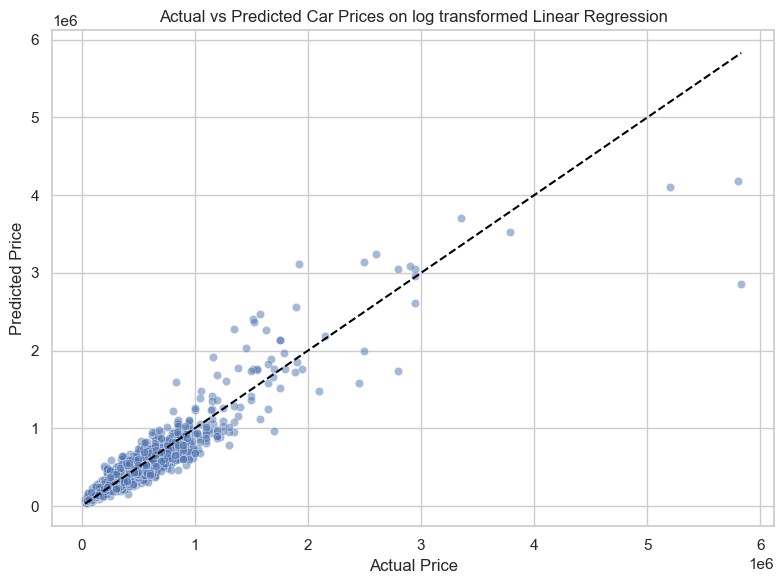

In [152]:
# Visualising differences between actual and predicted values on log-transformed Linear Regression model 
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test_original, y=y_pred, alpha=0.5)
plt.plot([y_test_original.min(), y_test_original.max()], [y_test_original.min(), y_test_original.max()], '--', color='black')  
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices on log transformed Linear Regression")
plt.tight_layout()
plt.show()

### **Alternative Models**

While linear regression provided a solid baseline with an R² of 71% and 85%, it assumes a linear relationship between features and the target. Real-world data like car prices often involve non-linear patterns and interactions that linear models can't fully capture. Random Forest and XGBoost are better suited for this kind of complexity—they can model non-linear relationships and handle subtle feature interactions without strong assumptions. Using them allows for a more flexible approach, potentially improving predictive accuracy beyond what linear methods can achieve.

### **RandomForest Regressor**

In [156]:
# Splitting the dataset
X = final_cars.drop(['selling_price', 'name', 'model'], axis=1) 
y = final_cars['selling_price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, oob_score=True)
rf_model.fit(X_train, y_train)

# Predict
y_pred = rf_model.predict(X_test)

In [157]:
# Evaluate the model
# Calculate Out-of-Bag (OOB) score
oob_score = rf_model.oob_score_
print(f'Out-of-Bag Score: {oob_score}')

# Calculate MSE
mse = mean_squared_error(y_test, y_pred)
print('Mean Squared Error:', mse)

# Calculate MAE
mae = mean_absolute_error(y_test, y_pred)
print('Mean Absolute Error:', mae)

# Calculate RMSE
rmse = np.sqrt(mse)
print('Root Mean Squared Error:', rmse)
# Caluculate R2 score
r2_square = r2_score(y_test,y_pred)
print('R-squared:', r2_square)

Out-of-Bag Score: 0.8974915256033666
Mean Squared Error: 11060562997.343748
Mean Absolute Error: 67393.94460506244
Root Mean Squared Error: 105169.21126139413
R-squared: 0.9485746686552831


The Random Forest model achieved an out-of-bag (OOB) score of 0.897, indicating strong generalisation performance during internal validation. The R² score on the test set was 0.949, meaning the model explains approximately 94.9% of the variance in car prices. While the mean squared error remains relatively large due to the scale of the target variable, the overall performance reflects a highly effective model fit.

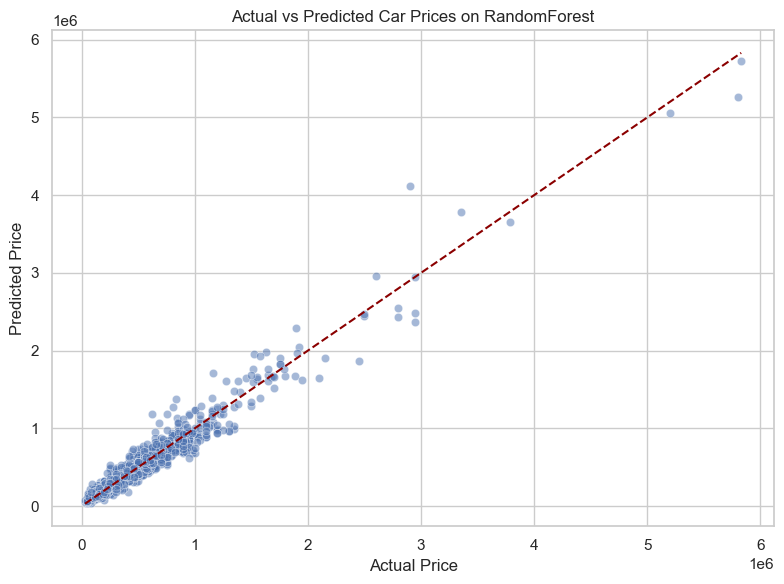

In [159]:
# Visualising differences between actual and predicted values on RandomForest model 
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='darkred')  # diagonal
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices on RandomForest")
plt.tight_layout()
plt.show()

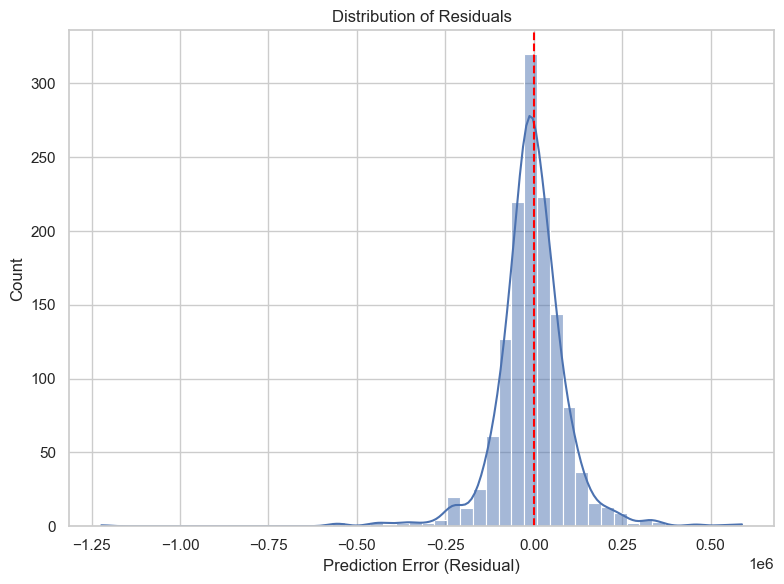

In [160]:
residuals = y_test - y_pred

plt.figure(figsize=(8,6))
sns.histplot(residuals, bins=50, kde=True)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel("Prediction Error (Residual)")
plt.title("Distribution of Residuals")
plt.tight_layout()
plt.show()

The residuals are approximately normally distributed and centered around zero, indicating that the model does not suffer from major bias in over- or under-fitting. While the majority of errors are small and symmetrically distributed, the presence of long tails suggests a few outliers where the model's predictions deviate significantly from actual prices. This is expected in real-world car pricing data and may be further mitigated with outlier handling or model tuning.

### **RandomForest on log transformed columns**

Earlier in the CodeBook, log transformations were used on skewed continuous data columns. To assess the differences, we will now compare the log transformed data to the regular dataset.

In [164]:
# Define X and y
X = log_final_cars.drop(['selling_price', 'name', 'model'], axis=1)
y = log_final_cars['selling_price']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
model = RandomForestRegressor(n_estimators=100, random_state=42, oob_score=True)
model.fit(X_train, y_train)

# Predict (still in log-scale)
y_pred_log = model.predict(X_test)

# Inverse transform for evaluation
y_test_original = np.expm1(y_test)
y_pred = np.expm1(y_pred_log)

In [165]:
# Evaluate the model
# Calculate Out-of-Bag (OOB) score
oob_score = model.oob_score_
print(f'Out-of-Bag Score: {oob_score}')

# Calculate MSE
mse = mean_squared_error(y_test_original, y_pred)
print('Mean Squared Error:', mse)

# Calculate MAE
mae = mean_absolute_error(y_test_original, y_pred)
print('Mean Absolute Error:', mae)

# Calculate RMSE
rmse = np.sqrt(mse)
print('Root Mean Squared Error:', rmse)

# Caluculate R2 score
r2_square = r2_score(y_test_original, y_pred)
print('R-squared:', r2_square)

Out-of-Bag Score: 0.904648506446047
Mean Squared Error: 12737730172.048254
Mean Absolute Error: 71298.37942926821
Root Mean Squared Error: 112861.55311729612
R-squared: 0.94077679455969


The Random Forest model, trained on log-transformed features and target, achieved an R² score of 0.941 and an out-of-bag score of 0.905. These values indicate that the model captures most of the variance in the log-transformed selling prices and generalises well to unseen data. Although the mean squared error appears large, it reflects squared differences in log-space and should be interpreted accordingly.

### **XGBoost Regressor**

In addition to Linear Regression and Random Forest, XGBoost was included to evaluate a more advanced, gradient boosting approach. While Linear Regression provides a simple, interpretable baseline, it assumes linear relationships and struggles with complex patterns. Random Forest improves on this by capturing non-linear interactions through ensemble decision trees, but it treats each tree independently. XGBoost goes a step further by building trees sequentially, with each new tree correcting the errors of the previous ones. This allows for greater model accuracy and better handling of subtle relationships in the data. Including XGBoost enables a fair performance comparison across linear, bagging, and boosting techniques.

In [169]:
# Drop name and define features + target
X = final_cars.drop(['selling_price', 'name', 'model'], axis=1)
y = final_cars['selling_price']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Training XGBoost Regressor
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

# Fitting model
xgb_model.fit(X_train, y_train)

# Predict
y_pred = xgb_model.predict(X_test)

In [170]:
# Evaluate the model
# Calculate MSE
mse = mean_squared_error(y_test, y_pred)
print('Mean Squared Error:', mse)

# Calculate MAE
mae = mean_absolute_error(y_test, y_pred)
print('Mean Absolute Error:', mae)

# Calculate RMSE
rmse = np.sqrt(mse)
print('Root Mean Squared Error:', rmse)

# Caluculate R2 score
r2_square = r2_score(y_test, y_pred)
print('R-squared:', r2_square)

Mean Squared Error: 12401485006.071825
Mean Absolute Error: 70599.90865832093
Root Mean Squared Error: 111361.9549310797
R-squared: 0.9423401355743408


The XGBoost model achieved an R² score of 0.942, indicating it explains over 94.2% of the variance in actual car prices. The RMSE of approximately ₹111,000 and MAE of around ₹70,600 reflect strong predictive accuracy given the wide price range in the dataset.

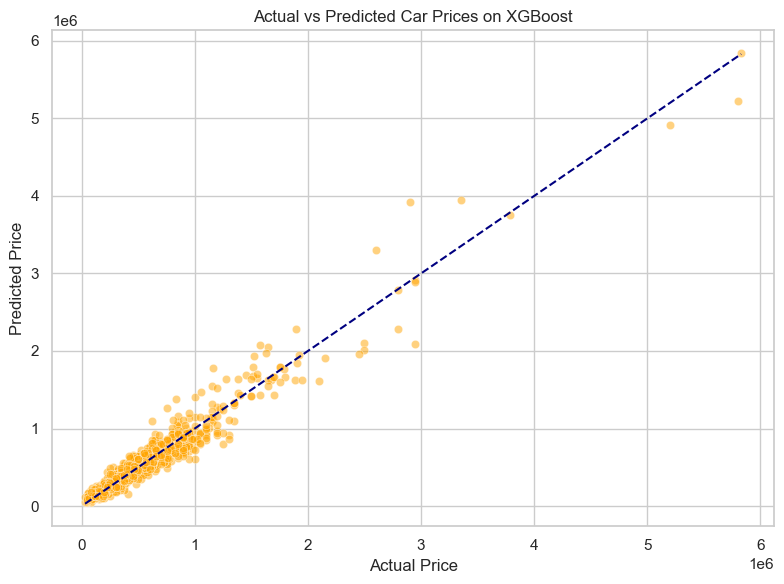

In [172]:
# Visualising differences between actual and predicted values on XGBoost model 
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred, color='orange', alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='navy') 
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices on XGBoost")
plt.tight_layout()
plt.show()

### **XGBoost on log transformed columns**

In [174]:
# Define X and y
X = log_final_cars.drop(['selling_price', 'name', 'model'], axis=1)
y = log_final_cars['selling_price']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

# Fitting model
xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],         
    early_stopping_rounds=10,            
    verbose=True                         
)

# Predict (still in log-scale)
y_pred_log = model.predict(X_test)

# Inverse transform for evaluation
y_true = np.expm1(y_test)
y_pred = np.expm1(y_pred_log)

[0]	validation_0-rmse:0.67673
[1]	validation_0-rmse:0.62199
[2]	validation_0-rmse:0.57623
[3]	validation_0-rmse:0.53420
[4]	validation_0-rmse:0.49759
[5]	validation_0-rmse:0.46481
[6]	validation_0-rmse:0.43544
[7]	validation_0-rmse:0.40923
[8]	validation_0-rmse:0.38603
[9]	validation_0-rmse:0.36567
[10]	validation_0-rmse:0.34739
[11]	validation_0-rmse:0.33397
[12]	validation_0-rmse:0.31979
[13]	validation_0-rmse:0.30795
[14]	validation_0-rmse:0.29780
[15]	validation_0-rmse:0.28850
[16]	validation_0-rmse:0.28055
[17]	validation_0-rmse:0.27483
[18]	validation_0-rmse:0.26853
[19]	validation_0-rmse:0.26292
[20]	validation_0-rmse:0.25862
[21]	validation_0-rmse:0.25354
[22]	validation_0-rmse:0.25068
[23]	validation_0-rmse:0.24771
[24]	validation_0-rmse:0.24539
[25]	validation_0-rmse:0.24213
[26]	validation_0-rmse:0.23959
[27]	validation_0-rmse:0.23743
[28]	validation_0-rmse:0.23575
[29]	validation_0-rmse:0.23440
[30]	validation_0-rmse:0.23340
[31]	validation_0-rmse:0.23197
[32]	validation_0-

In [175]:
# Evaluate the model
# Calculate MSE
mse = mean_squared_error(y_true, y_pred)
print('Mean Squared Error:', mse)

# Calculate MAE
mae = mean_absolute_error(y_true, y_pred)
print('Mean Absolute Error:', mae)

# Calculate RMSE
rmse = np.sqrt(mse)
print('Root Mean Squared Error:', rmse)

# Caluculate R2 score
r2_square = r2_score(y_true, y_pred)
print('R-squared:', r2_square)

Mean Squared Error: 12737730172.048254
Mean Absolute Error: 71298.37942926821
Root Mean Squared Error: 112861.55311729612
R-squared: 0.94077679455969


The XGBoost model, trained with log-processed nominal features, achieved strong performance with an R² of 0.941, MAE of ₹71,300 and RMSE of ₹113,000, indicating accurate predictions and effective preprocessing.

**Learning curve/ validation curve**

Using a learning curve will check whether the model is underfitting/overfitting, in turn evaluating model scalability.

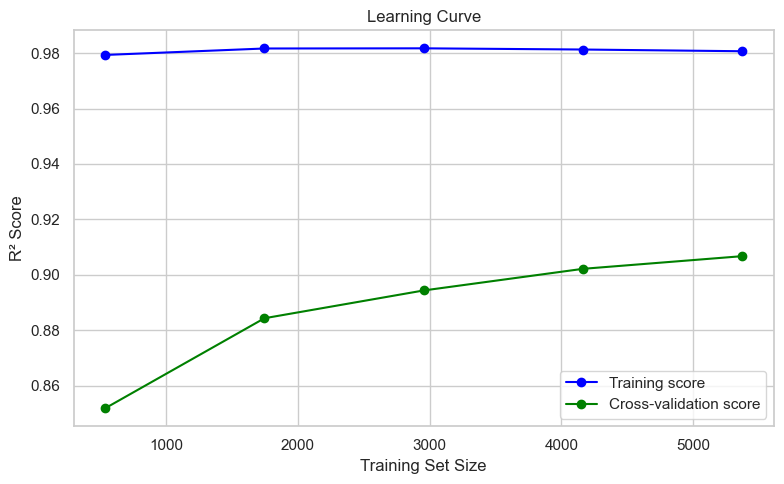

In [179]:
# Learning curve
# Set up cross-validation strategy
cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=42)

# Get learning curve data
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    cv=cv,
    scoring='r2', 
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

# Compute mean and std for plotting
train_scores_mean = np.mean(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)

# Plotting the learning curve
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores_mean, 'o-', color='blue', label='Training score')
plt.plot(train_sizes, test_scores_mean, 'o-', color='green', label='Cross-validation score')
plt.title('Learning Curve')
plt.xlabel('Training Set Size')
plt.ylabel('R² Score')
plt.legend(loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()

Learning curve insights:

The learning curve shows that the model has high variance (overfitting). The training score is consistently high (~0.98), while the cross-validation score is lower but still improving as more data is added. This suggests the model is complex and has memorized the training data.

Next Steps: The upward trend in the cross-validation score indicates that gathering more training data is likely the most effective way to improve the model's generalization performance.